# Baseball Trajectory Modeling with Air Resistance

This project is adapted from my Differential Equations homework. I modeled the motion of a baseball with four different assumptions about air resistance, and used equations of motion and `solve_ivp` to plot the trajectories. The  question here is how much air resistance changes the distance the ball travels.

## Setup

The position is $(x,y)$ and velocity is $(u,v)$. The numerical solver stops when the ball returns to the ground.

**Controlled comparison:** All four models use the same initial speed (50 m/s), launch angle (45°), launch position (0, 0), and gravitational acceleration (9.8 m/s²). Only the treatment of drag changes.

In [1]:
import numpy as np
import matplotlib as mpl
import matplotlib.pyplot as plt
from scipy import integrate
mpl.rcParams['font.size'] = 12
%config InlineBackend.figure_format = 'retina'

pi = np.pi
e  = np.e

def landing(t, vec):
    return vec[1]
landing.direction = -1
landing.terminal = True
# Same launch conditions for every model
launch_speed = 50  # m/s
launch_angle = 45  # degrees


## 1. No air resistance

### Equations of motion

$x' = u$, $y' = v$

$u' = 0$, $v' = -g$

with initial conditions

$x(0)=0$, $y(0)=0$

$u(0)=v_0\cos(\theta)$, $v(0)=v_0\sin(\theta)$

solve for $u$:

$u' = 0$

Integrate,

$u = v_0\cos(\theta)$

Since $x' = u$,

$x(t) = v_0\cos(\theta)t$

solve for $v$:

$v' = -g$

Integrating,

$v = v_0\sin(\theta) - gt$

Since $y' = v$,

$y(t) = v_0\sin(\theta)t - \frac{1}{2}gt^2$

The parametric equations are

$x(t) = v_0\cos(\theta)t$

$y(t) = v_0\sin(\theta)t - \frac{1}{2}gt^2$

### Trajectory equation

From part (a),

$x(t) = v_0\cos(\theta)t$

$y(t) = v_0\sin(\theta)t - \frac{1}{2}gt^2$

Solve for $t$:

$t = \frac{x}{v_0\cos(\theta)}$

Now substitute this into the formula for $y(t)$:

$y = v_0\sin(\theta)\left(\frac{x}{v_0\cos(\theta)}\right) - \frac{1}{2}g\left(\frac{x}{v_0\cos(\theta)}\right)^2$

Simplify:

$y = x\tan(\theta) - \frac{1}{2}g\frac{x^2}{v_0^2\cos^2(\theta)}$

The explicit equation for the trajectory is

$y = x\tan(\theta) - \frac{g}{2v_0^2\cos^2(\theta)}x^2$

### Maximum range without drag

The ball lands when $y=0$. From part (b):

$0 = x\tan(\theta) - \frac{g}{2v_0^2\cos^2(\theta)}x^2$

The nonzero solution gives the range $R$:

$R = \frac{2v_0^2\sin(\theta)\cos(\theta)}{g}$

Using $2\sin(\theta)\cos(\theta) = \sin(2\theta)$:

$R = \frac{v_0^2}{g}\sin(2\theta)$

The maximum value of $\sin(2\theta)$ is $1$, which occurs when

$2\theta = 90^\circ$

so

$\theta = 45^\circ$.

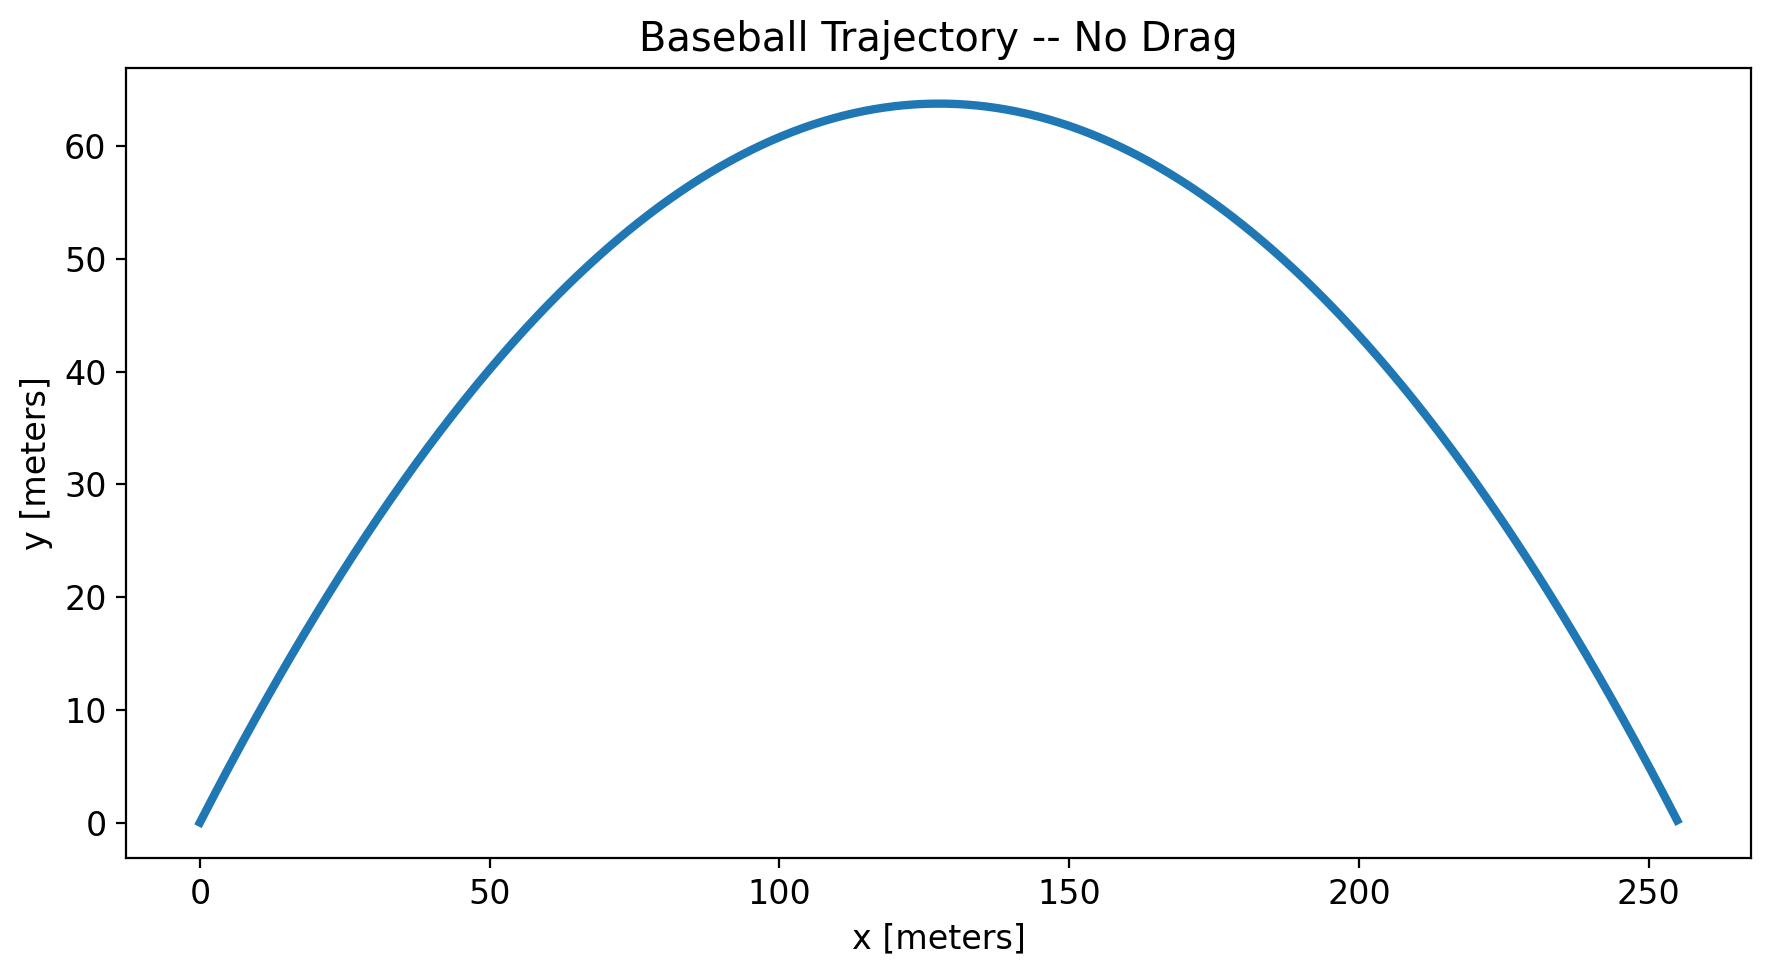

Landing distance = 255.1 meters


In [2]:
def rhs1(t, vec):
    
    x = vec[0]
    y = vec[1]
    u = vec[2]
    v = vec[3]

    
    dxdt  = u
    dydt  = v
    
    # calculate the speed
    speed = np.sqrt(u**2 + v**2)
    
    # define the accelerations acting on the ball
    dudt  = 0
    dvdt  = -9.8
    
    return [dxdt, dydt, dudt, dvdt]


x0 = 0
y0 = 0
u0 = launch_speed*np.cos(np.deg2rad(launch_angle))
v0 = launch_speed*np.sin(np.deg2rad(launch_angle))
ICs = [x0, y0, u0, v0]

times  = np.linspace(0, 10, 1001)
bounds = (times[0], times[-1])
result = integrate.solve_ivp(rhs1, bounds, ICs, t_eval=times, events=[landing])


t = result["t"]
x = result["y"][0]
y = result["y"][1]
u = result["y"][2]
v = result["y"][3]

plt.figure(figsize=(9,5))
plt.plot(x,y, lw=3)
plt.xlabel("x [meters]")
plt.ylabel("y [meters]")
plt.title("Baseball Trajectory -- No Drag")
plt.tight_layout()
plt.savefig('baseball_no_drag.png')
plt.show()
print("Landing distance =", round(result.y_events[0][0][0], 2), "meters")


## 2. Linear air resistance

The equations are

$x' = u$, $y' = v$

$u' = -\frac{\delta_1}{m}u$, $v' = -g - \frac{\delta_1}{m}v$

with

$x(0)=0$, $y(0)=0$

$u(0)=50\cos(45^\circ)$, $v(0)=50\sin(45^\circ)$

Solve for $u$:

$u' = -\frac{\delta_1}{m}u$

$u(t) = 50\cos(45^\circ)e^{-\frac{\delta_1}{m}t}$

Since $x' = u$,

$x(t) = \frac{50m\cos(45^\circ)}{\delta_1}\left(1-e^{-\frac{\delta_1}{m}t}\right)$

Solve for $v$:

$v' = -g - \frac{\delta_1}{m}v$

$v(t)=\left(50\sin(45^\circ)+\frac{mg}{\delta_1}\right)e^{-\frac{\delta_1}{m}t}-\frac{mg}{\delta_1}$

Since $y' = v$,

$y(t)=\frac{m}{\delta_1}\left(50\sin(45^\circ)+\frac{mg}{\delta_1}\right)\left(1-e^{-\frac{\delta_1}{m}t}\right)-\frac{mg}{\delta_1}t$

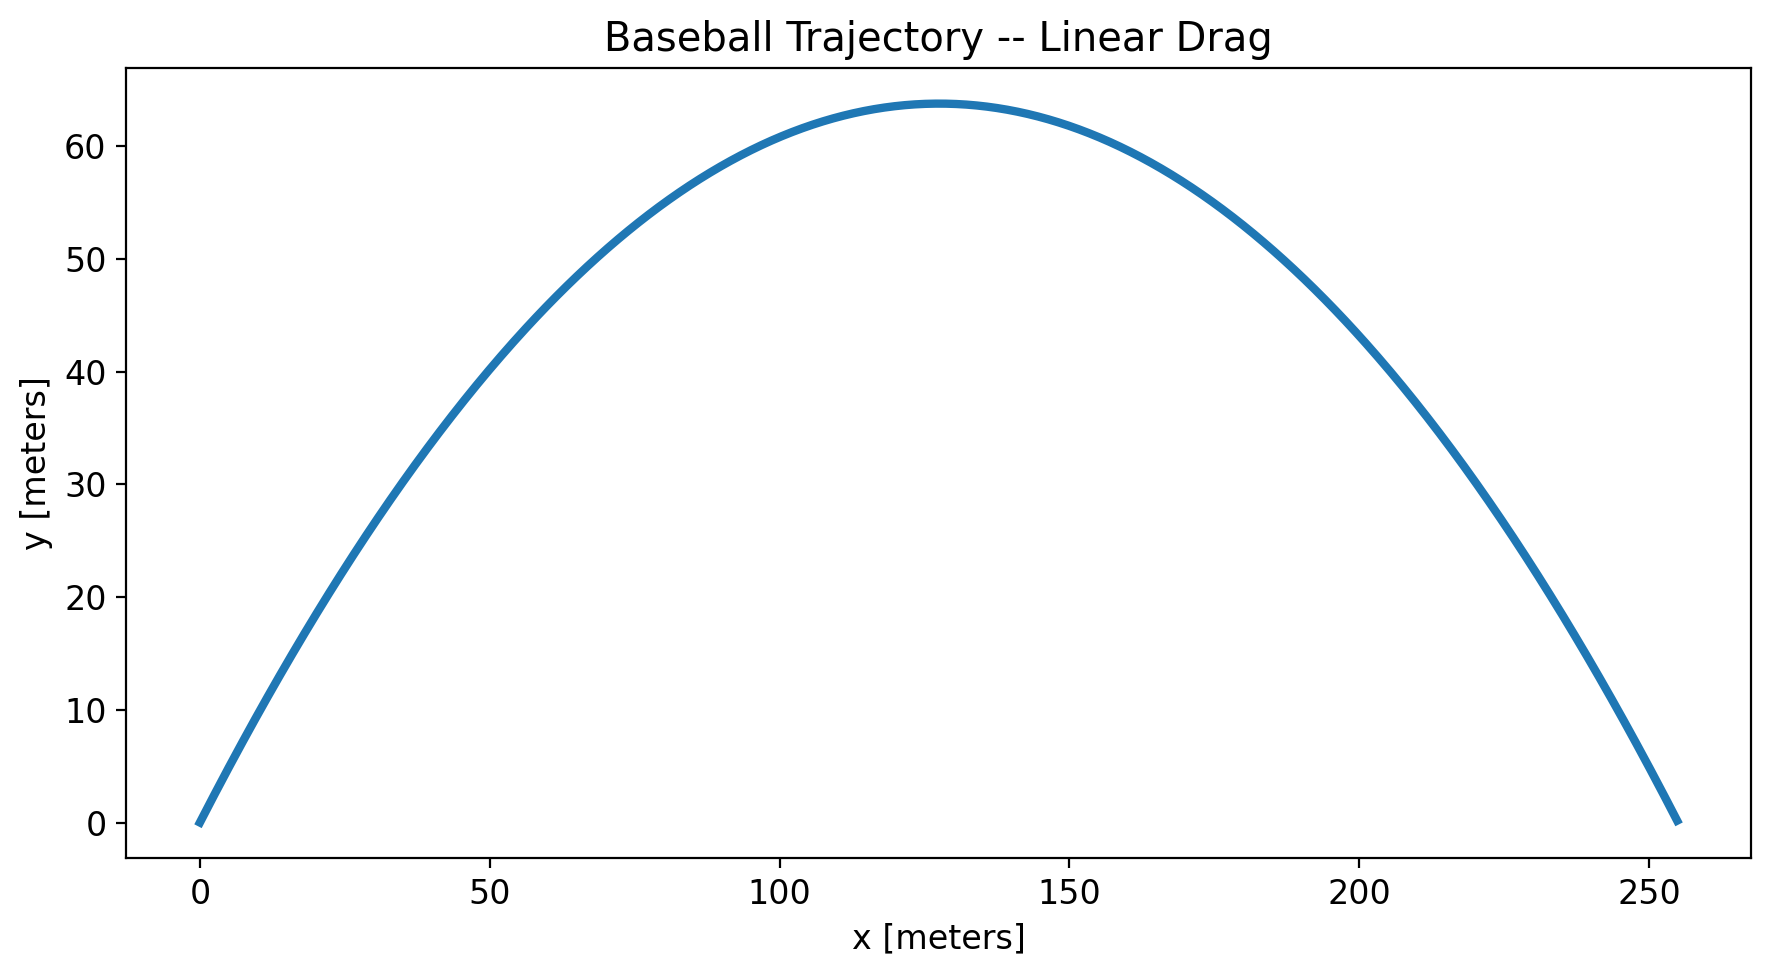

Landing distance = 255.0 meters


In [3]:
m = 0.145
r = 0.0366
eta = 1.8e-5

delta1 = 6*np.pi*eta*r

def rhs1(t, vec):
    

    x = vec[0]
    y = vec[1]
    u = vec[2]
    v = vec[3]

    # give new names to dxdt and dydt
    dxdt  = u
    dydt  = v
    
    # calculate the speed
    speed = np.sqrt(u**2 + v**2)
    
    # define the accelerations acting on the ball
    dudt  = -(delta1/m)*u
    dvdt  =  -9.8 -(delta1/m)*v
    
    
    return [dxdt, dydt, dudt, dvdt]



x0 = 0
y0 = 0
u0 = launch_speed*np.cos(np.deg2rad(launch_angle))
v0 = launch_speed*np.sin(np.deg2rad(launch_angle))
ICs = [x0, y0, u0, v0]


times  = np.linspace(0, 10, 1001)
bounds = (times[0], times[-1])
result = integrate.solve_ivp(rhs1, bounds, ICs, t_eval=times, events=[landing])


t = result["t"]
x = result["y"][0]
y = result["y"][1]
u = result["y"][2]
v = result["y"][3]


plt.figure(figsize=(9,5))
plt.plot(x,y, lw=3)
plt.xlabel("x [meters]")
plt.ylabel("y [meters]")
plt.title("Baseball Trajectory -- Linear Drag")
plt.tight_layout()
plt.savefig('baseball_linear_drag.png')
plt.show()
print("Landing distance =", round(result.y_events[0][0][0], 2), "meters")


### Observation
With a 50 m/s launch at 45°, linear drag predicts approximately **255.00 m**, versus **255.10 m** without drag. The difference is very small because the Stokes drag coefficient used here is extremely small for a baseball. This linear model therefore does not capture the large influence of air resistance on a real baseball at this speed.

## 3. Quadratic air resistance

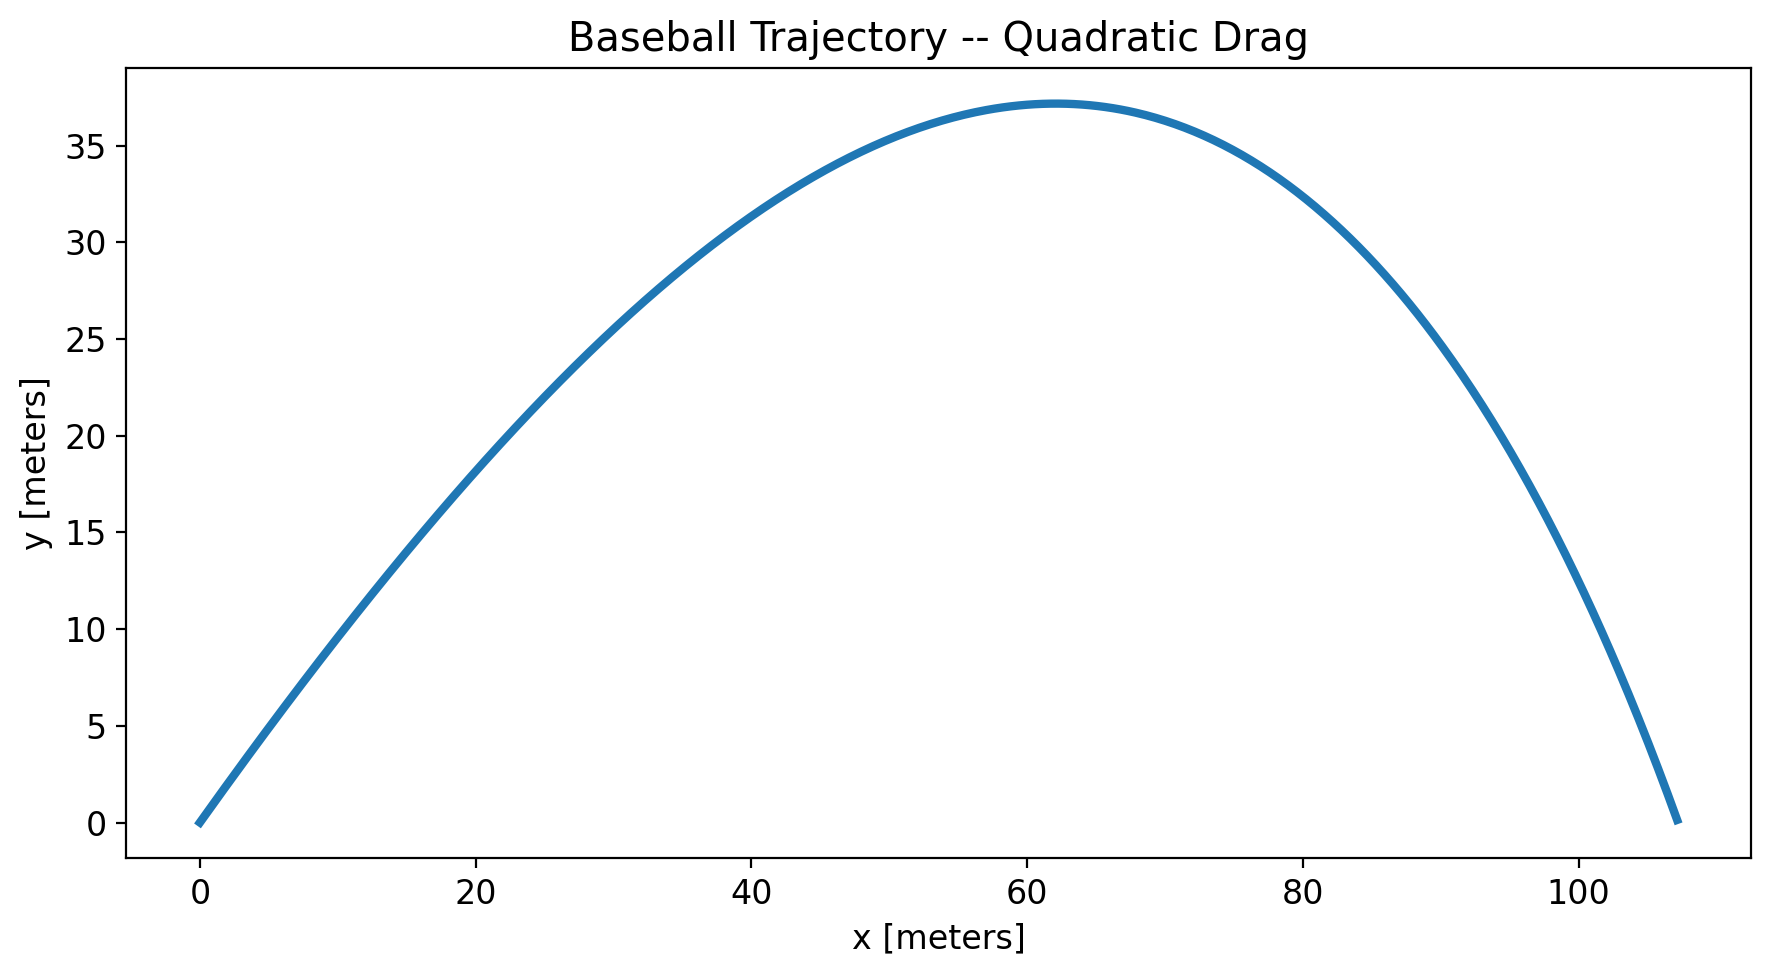

Landing distance = 107.22 meters


In [4]:
m = 0.145
r = 0.0366
rho = 1.225
Cd = 0.47
A = np.pi*r**2

delta2 = 0.5*rho*Cd*A
def rhs1(t, vec):
    
   
    x = vec[0]
    y = vec[1]
    u = vec[2]
    v = vec[3]

  
    dxdt  = u
    dydt  = v
    
   
    speed = np.sqrt(u**2 + v**2)
    
    # define the accelerations acting on the ball
    dudt = -(delta2/m)*u*speed  # horizontal acceleration due to drag
    dvdt = -9.8 -(delta2/m)*v*speed

    
  
    return [dxdt, dydt, dudt, dvdt]
    


x0 = 0
y0 = 0
u0 = launch_speed*np.cos(np.deg2rad(launch_angle))
v0 = launch_speed*np.sin(np.deg2rad(launch_angle))
ICs = [x0, y0, u0, v0]

# set up the time variable
times  = np.linspace(0, 10, 1001)
bounds = (times[0], times[-1])
result = integrate.solve_ivp(rhs1, bounds, ICs, t_eval=times, events=[landing])


t = result["t"]
x = result["y"][0]
y = result["y"][1]
u = result["y"][2]
v = result["y"][3]

plt.figure(figsize=(9,5))
plt.plot(x,y, lw=3)
plt.xlabel("x [meters]")
plt.ylabel("y [meters]")
plt.title("Baseball Trajectory -- Quadratic Drag")
plt.tight_layout()
plt.savefig('baseball_quadratic_drag.png')
plt.show()

print("Landing distance =", round(result.y_events[0][0][0], 2), "meters")


## 3. Quadratic air resistance (b)

At the shared launch conditions (50 m/s, 45°), the quadratic-drag model predicts a range of approximately **107.19 m**. This is substantially shorter than the no-drag and linear-drag predictions.

## 3. Quadratic air resistance (c)

In a separate launch-angle test, I found an approximately optimal angle of **39°** for the quadratic-drag model, below the 45° optimum without air resistance. The comparison plots above still use 45° for consistency.

## 3. Quadratic air resistance (d)

In a separate launch-speed test at about 39°, I estimated that a launch speed near **60 m/s** was needed to reach around 130 m with quadratic drag. That speed is **not** the 50 m/s used in the controlled comparison.

## 4. Speed-dependent drag coefficient (drag crisis)

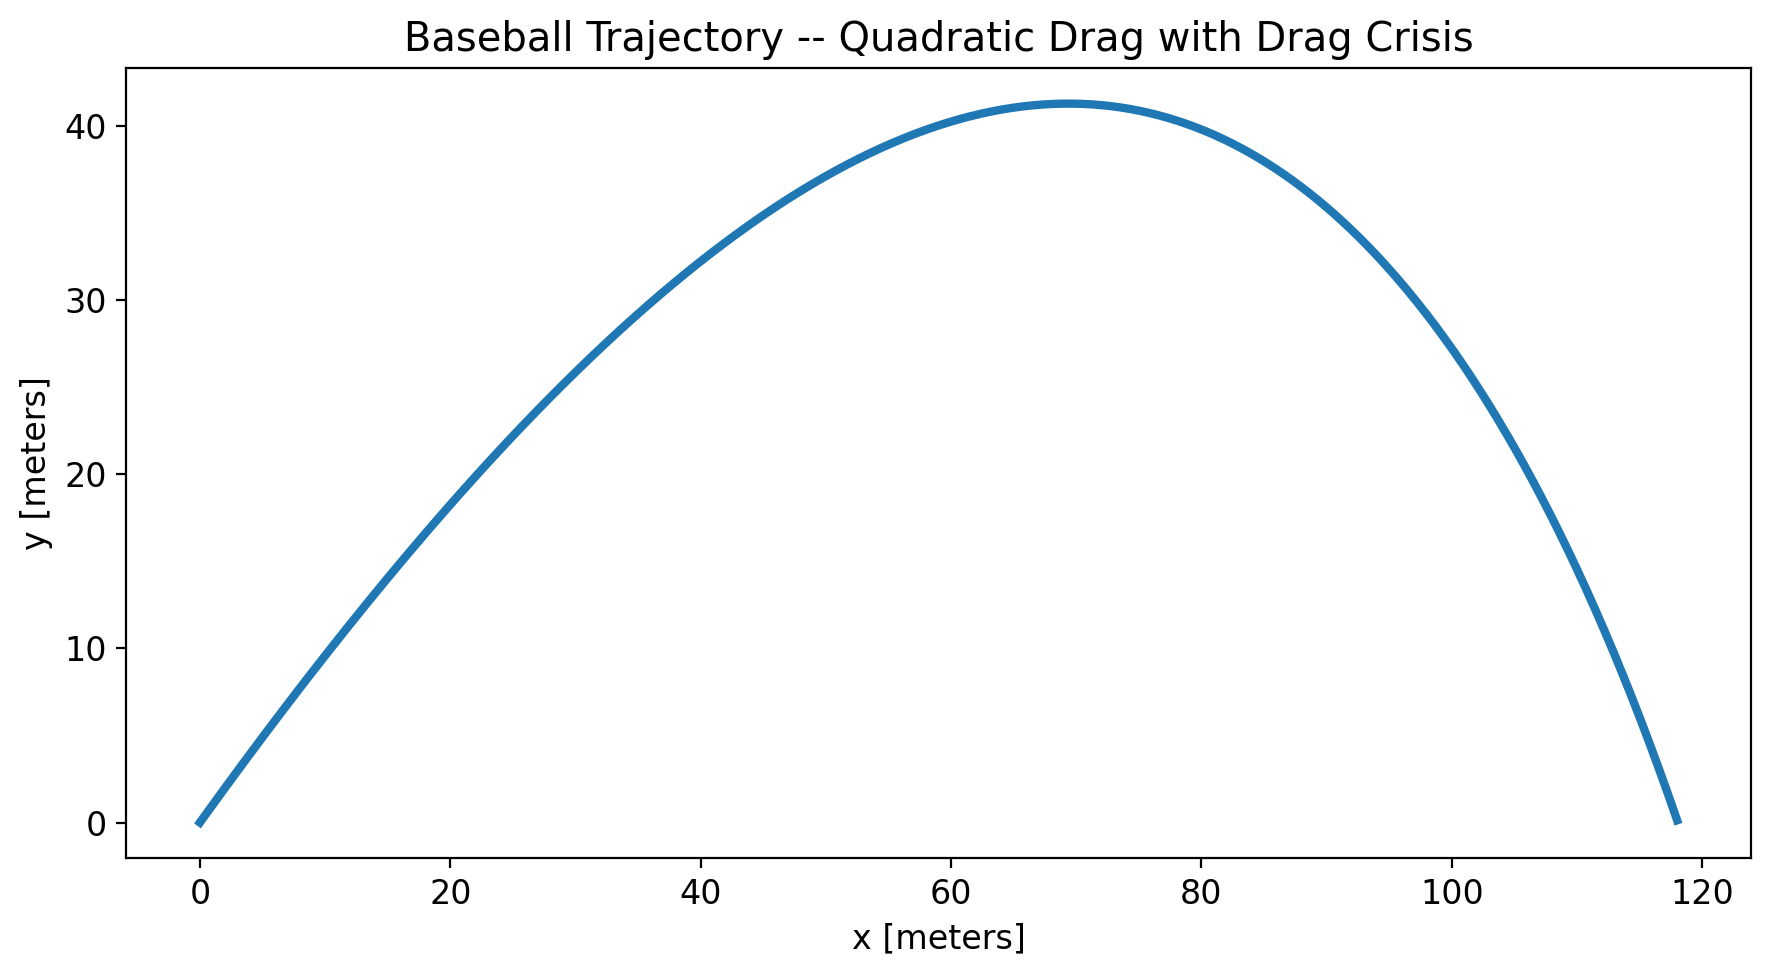

Landing distance = 118.05 meters


In [5]:
m = 0.145
r = 0.0366
rho = 1.225
A = np.pi*r**2

def rhs1(t, vec):
    
    
    x = vec[0]
    y = vec[1]
    u = vec[2]
    v = vec[3]

    dxdt  = u
    dydt  = v
    
    speed = np.sqrt(u**2 + v**2)
    Cd = 0.29 + 0.22/(1 + np.exp((speed - 32.4)/5.2))
    delta2 = 0.5*rho*Cd*A
    
  
    dudt =  -(delta2/m)*u*speed  # horizontal acceleration due to drag
    dvdt =  -9.8 -(delta2/m)*v*speed

    return [dxdt, dydt, dudt, dvdt]
    

x0 = 0
y0 = 0
u0 = launch_speed*np.cos(np.deg2rad(launch_angle))
v0 = launch_speed*np.sin(np.deg2rad(launch_angle))
ICs = [x0, y0, u0, v0]


times  = np.linspace(0, 10, 1001)
bounds = (times[0], times[-1])
result = integrate.solve_ivp(rhs1, bounds, ICs, t_eval=times, events=[landing])


t = result["t"]
x = result["y"][0]
y = result["y"][1]
u = result["y"][2]
v = result["y"][3]


plt.figure(figsize=(9,5))
plt.plot(x,y, lw=3)
plt.xlabel("x [meters]")
plt.ylabel("y [meters]")
plt.title("Baseball Trajectory -- Quadratic Drag with Drag Crisis")
plt.tight_layout()
plt.savefig('baseball_drag_crisis.png')
plt.show()

print("Landing distance =", round(result.y_events[0][0][0], 2), "meters")


## 4. Speed-dependent drag coefficient (drag crisis) (b)

At the shared launch conditions (50 m/s, 45°), the speed-dependent drag model predicts a range of approximately **118.04 m**. Its prediction differs from constant-coefficient quadratic drag because the drag coefficient changes as the ball slows down.

## 4. Speed-dependent drag coefficient (drag crisis) (c)

In a separate launch-angle test, I found the optimal angle to be approximately **37°** when including the speed-dependent drag coefficient. The main comparison still uses 45° for all four models.

## 4. Speed-dependent drag coefficient (drag crisis) (d)

In a separate speed test at about 37°, a launch speed around **53 m/s** gave a range near 130 m. This is a separate experiment from the controlled comparison at 50 m/s and 45°.

## Conclusion

Keeping the launch speed at **50 m/s** and the launch angle at **45°** across all four models makes it possible to compare the effects of air resistance directly. With no drag, the baseball travels approximately **255.10 m**. Linear drag predicts almost the same result (**255.00 m**), while quadratic drag shortens the range considerably (**107.19 m**). The speed-dependent drag model gives **118.04 m**.

The main takeaway is that **the choice of drag model matters**. Linear resistance has very little effect under the chosen parameters, while models that include velocity-squared drag predict much shorter flights. Allowing the drag coefficient to depend on speed changes the trajectory again.

I also explored different launch angles and speeds separately. Those tests suggest that the range-maximizing angle with drag is below 45°, but the four main trajectories use identical launch conditions.

*This project builds on a Differential Equations assignment, using numerical integration in SciPy to compare baseball-flight models.*

## Side-by-side comparison

All four curves below use the same initial speed and angle. Their different ranges are caused by the drag assumptions.

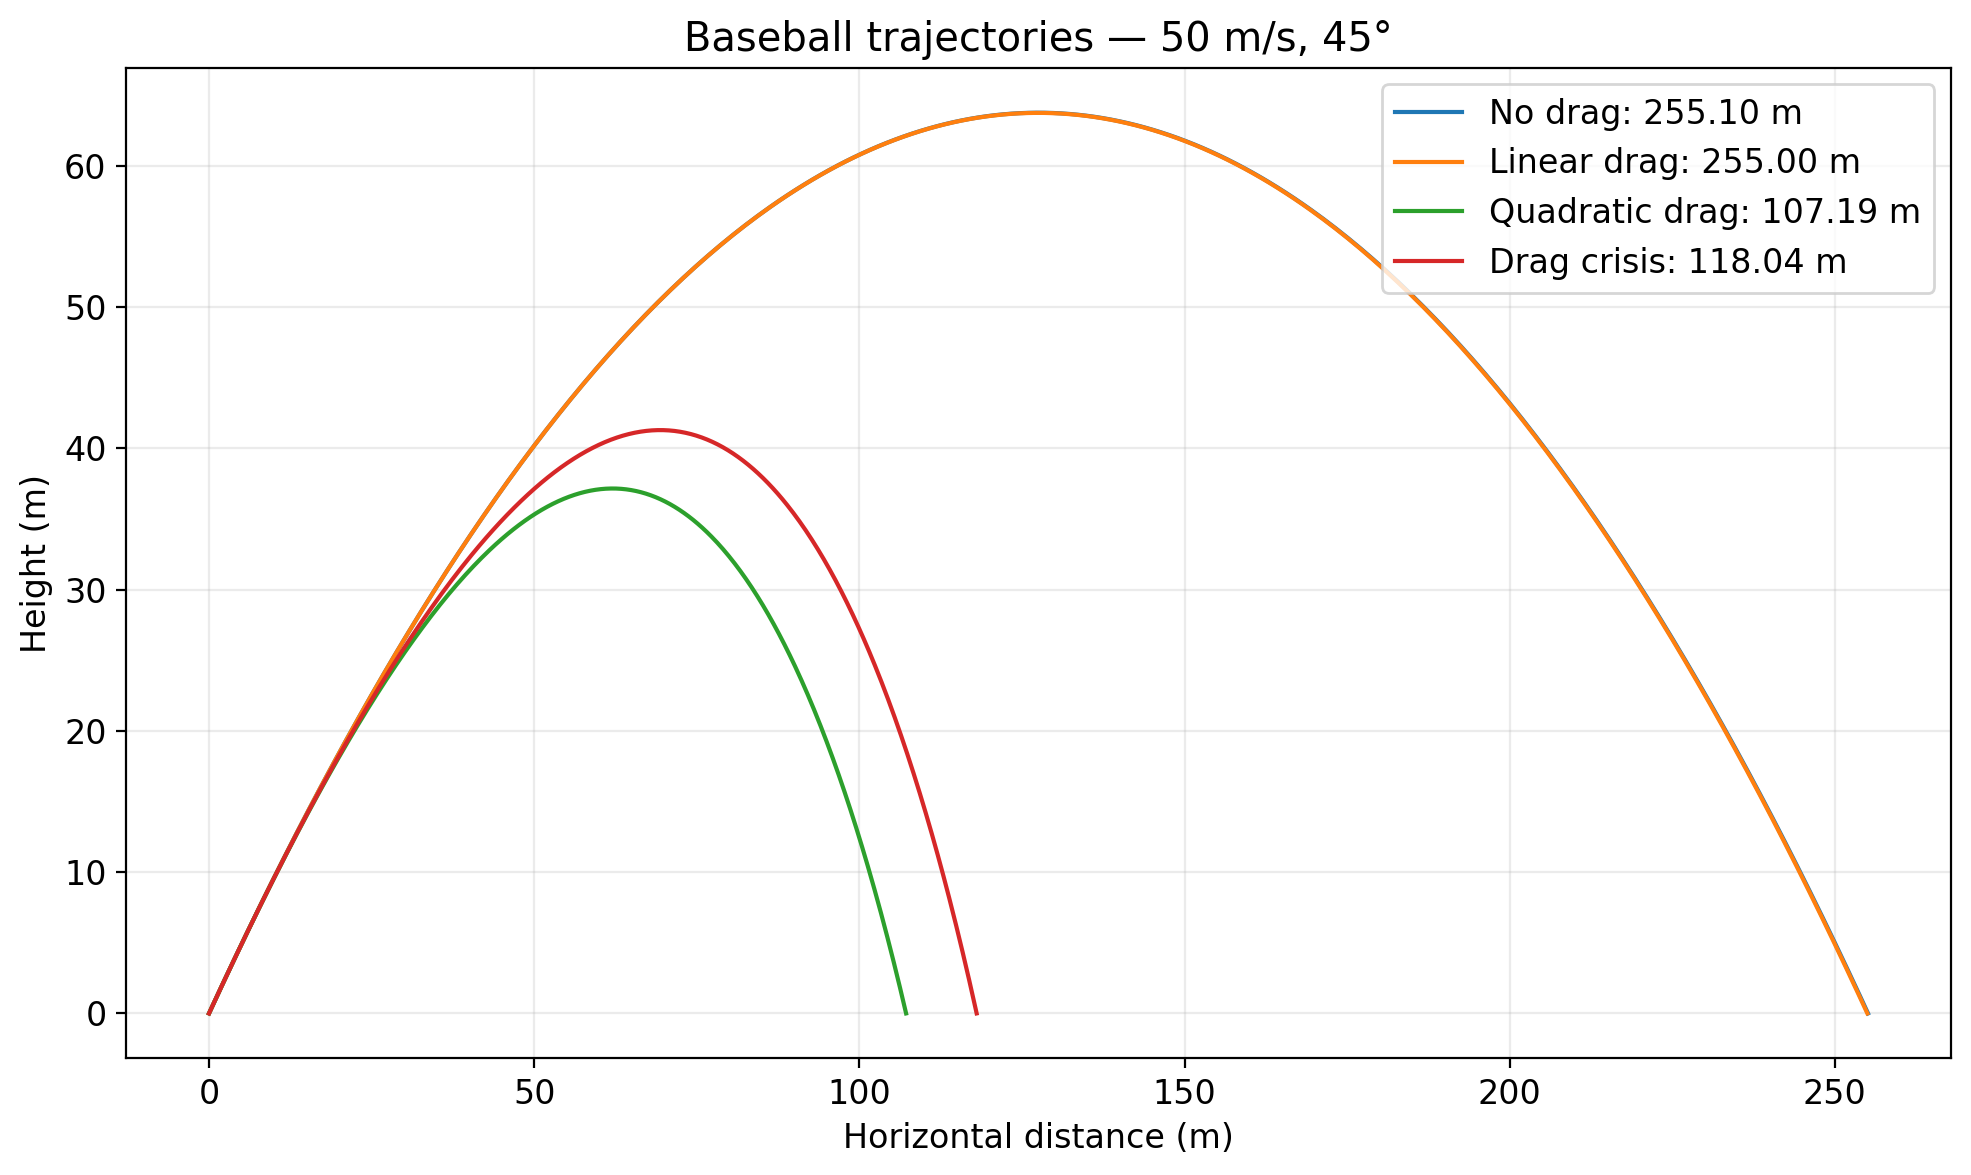

In [6]:
# Plot the four models together with identical launch conditions
m = 0.145
r = 0.0366
rho = 1.225
A = np.pi*r**2
eta = 1.8e-5

def simulate(model):
    def motion(t, vec):
        x, y, u, v = vec
        speed = np.sqrt(u**2 + v**2)
        if model == "No drag":
            dudt = 0
            dvdt = -9.8
        elif model == "Linear drag":
            delta1 = 6*np.pi*eta*r
            dudt = -(delta1/m)*u
            dvdt = -9.8 - (delta1/m)*v
        else:
            Cd = 0.47
            if model == "Drag crisis":
                Cd = 0.29 + 0.22/(1 + np.exp((speed - 32.4)/5.2))
            delta2 = 0.5*rho*Cd*A
            dudt = -(delta2/m)*u*speed
            dvdt = -9.8 - (delta2/m)*v*speed
        return [u, v, dudt, dvdt]

    initial = [0, 0,
               launch_speed*np.cos(np.deg2rad(launch_angle)),
               launch_speed*np.sin(np.deg2rad(launch_angle))]
    return integrate.solve_ivp(motion, (0, 10), initial,
                               dense_output=True, events=[landing],
                               rtol=1e-8, atol=1e-10)

plt.figure(figsize=(10, 6))
for name in ["No drag", "Linear drag", "Quadratic drag", "Drag crisis"]:
    sol = simulate(name)
    flight_time = sol.t_events[0][0]
    t_plot = np.linspace(0, flight_time, 400)
    xy = sol.sol(t_plot)
    plt.plot(xy[0], xy[1], label=f"{name}: {sol.y_events[0][0][0]:.2f} m")

plt.xlabel("Horizontal distance (m)")
plt.ylabel("Height (m)")
plt.title("Baseball trajectories — 50 m/s, 45°")
plt.legend()
plt.grid(alpha=0.25)
plt.tight_layout()
plt.show()